<a href="https://colab.research.google.com/github/gyanadhaanainar/signlanguage_recognition/blob/main/signlanguage.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [11]:
DATA_DIR = (
    "/content/drive/MyDrive/SignLanguageDetection/dataset"
)

In [12]:
!cp -r /content/drive/MyDrive/SignLanguageDetection/asl_alphabet_train /content/data

In [13]:
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models


In [14]:
DATA_DIR = "/content/drive/MyDrive/SignLanguageDetection/asl_alphabet_train/asl_alphabet_train"

IMG_SIZE = (64, 64)
BATCH_SIZE = 32
SEED = 123

In [15]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)


Found 13270 files belonging to 29 classes.
Using 10616 files for training.


In [16]:
val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

Found 13270 files belonging to 29 classes.
Using 2654 files for validation.


In [20]:
train_ds = train_ds.cache().prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.cache().prefetch(tf.data.AUTOTUNE)

In [25]:
import os
class_names = sorted([
    folder for folder in os.listdir(DATA_DIR)
    if os.path.isdir(os.path.join(DATA_DIR, folder))
])

num_classes = len(class_names)

print("Classes:", class_names)
print("Number of classes:", num_classes)

Classes: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'del', 'nothing', 'space']
Number of classes: 29


In [26]:
num_classes = len(class_names)

model = models.Sequential([
    layers.Input(shape=(64, 64, 3)),

    # Normalize pixels from 0-255 to 0-1
    layers.Rescaling(1.0 / 255),

    # First convolution block
    layers.Conv2D(
        32, (3, 3), activation="relu",
        padding="same"
    ),
    layers.MaxPooling2D((2, 2)),

    # Second convolution block
    layers.Conv2D(
        64, (3, 3), activation="relu",
        padding="same"
    ),
    layers.MaxPooling2D((2, 2)),

    # Third convolution block
    layers.Conv2D(
        128, (3, 3), activation="relu",
        padding="same"
    ),
    layers.MaxPooling2D((2, 2)),

    # Classification layers
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(num_classes, activation="softmax")
])

In [27]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 29)             │         3,741 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,145,693 (4.37 MB)

 Trainable params: 1,145,693 (4.37 MB)

 Non-trainable params: 0 (0.00 B)

In [28]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)


In [29]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[early_stop]
)


Epoch 1/15
332/332 ━━━━━━━━━━━━━━━━━━━━ 34s 76ms/step - accuracy: 0.6938 - loss: 0.7905 - val_accuracy: 0.8937 - val_loss: 0.2480
Epoch 2/15
332/332 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8915 - loss: 0.2564 - val_accuracy: 0.9152 - val_loss: 0.1594
Epoch 3/15
332/332 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9245 - loss: 0.1811 - val_accuracy: 0.9314 - val_loss: 0.1710
Epoch 4/15
332/332 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9430 - loss: 0.1383 - val_accuracy: 0.9759 - val_loss: 0.0602
Epoch 5/15
332/332 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9602 - loss: 0.1036 - val_accuracy: 0.9725 - val_loss: 0.0519
Epoch 6/15
332/332 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9743 - loss: 0.0675 - val_accuracy: 0.9879 - val_loss: 0.0305
Epoch 7/15
332/332 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9812 - loss: 0.0512 - val_accuracy: 0.9891 - val_loss: 0.0225
Epoch 8/15
332/332 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9845 - loss: 0.0512 - val_accuracy: 

In [30]:
model.save("sign_language_cnn.keras")
print("Model saved successfully!")

Model saved successfully!


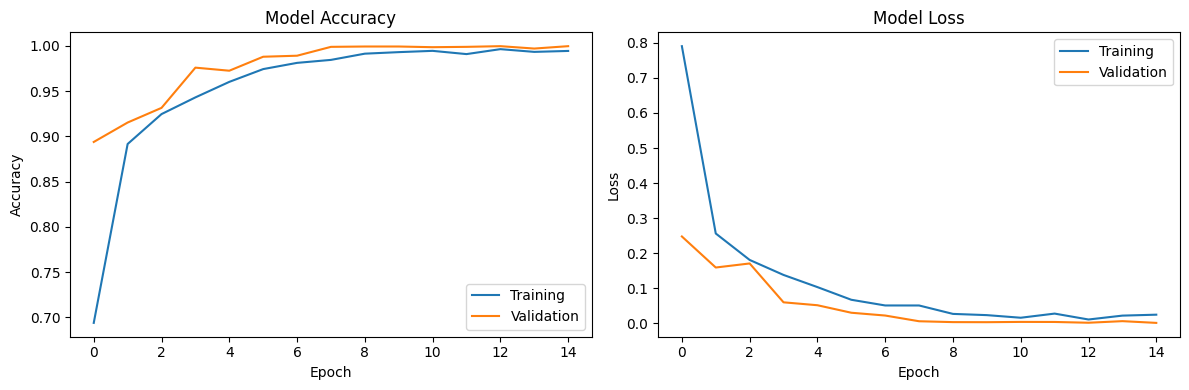

In [31]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [34]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

svm_model = SVC(kernel="rbf", C=5)
svm_model.fit(X_train_scaled, y_train)

svm_pred = svm_model.predict(X_test_scaled)

print("SVM Accuracy:", accuracy_score(y_test, svm_pred))
print(classification_report(
    y_test, svm_pred,
    labels=np.arange(len(class_names_ml)),
    target_names=class_names_ml,
    zero_division=0
))

NameError: name 'X_train_scaled' is not defined

In [33]:
import tensorflow as tf
import numpy as np

from tensorflow.keras.utils import load_img, img_to_array

model = tf.keras.models.load_model(
    "sign_language_cnn.keras"
)

# Must match the class folder names used during training
class_names = [
    'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'del', 'nothing', 'space'
]

image_path = "my_sign.jpg"

img = load_img(
    image_path,
    target_size=(64, 64)
)

img_array = img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)

predictions = model.predict(img_array, verbose=0)[0]

predicted_index = np.argmax(predictions)
predicted_sign = class_names[predicted_index]
confidence = predictions[predicted_index] * 100

print("Predicted sign:", predicted_sign)
print(f"Confidence: {confidence:.2f}%")

FileNotFoundError: [Errno 2] No such file or directory: 'my_sign.jpg'